# Iris classification — baseline experiment

Train a RandomForest on the Iris dataset and report **accuracy** and **macro F1-score** on a held-out test set. This notebook is the exploratory version; the same logic is split into `src/prepare.py`, `src/train.py` and `src/evaluate.py` for the DVC pipeline.

In [1]:
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

## 1. Load data

In [2]:
iris = load_iris(as_frame=True)
df = iris.frame
df.columns = ["sepal_length", "sepal_width", "petal_length", "petal_width", "target"]
print(df.shape)
print(df["target"].value_counts().sort_index())
df.head()

(150, 5)
target
0    50
1    50
2    50
Name: count, dtype: int64


,sepal_length,sepal_width,petal_length,petal_width,target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


## 2. Train / test split
Stratified 70/30 split so each class is equally represented.

In [3]:
TEST_SIZE = 0.3
RANDOM_STATE = 42

X, y = df.drop(columns="target"), df["target"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y
)
print(f"train: {len(X_train)}  test: {len(X_test)}")

train: 105  test: 45


## 3. Train the model

In [4]:
N_ESTIMATORS = 100
MAX_DEPTH = 3

model = RandomForestClassifier(n_estimators=N_ESTIMATORS, max_depth=MAX_DEPTH, random_state=RANDOM_STATE)
model.fit(X_train, y_train)

RandomForestClassifier(max_depth=3, random_state=42)

## 4. Evaluate

In [5]:
preds = model.predict(X_test)
accuracy = accuracy_score(y_test, preds)
f1 = f1_score(y_test, preds, average="macro")
print(f"Accuracy : {accuracy:.4f}")
print(f"F1 (macro): {f1:.4f}")
print()
print(classification_report(y_test, preds, target_names=iris.target_names))

Accuracy : 0.9111
F1 (macro): 0.9107

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.82      0.93      0.88        15
   virginica       0.92      0.80      0.86        15

    accuracy                           0.91        45
   macro avg       0.92      0.91      0.91        45
weighted avg       0.92      0.91      0.91        45



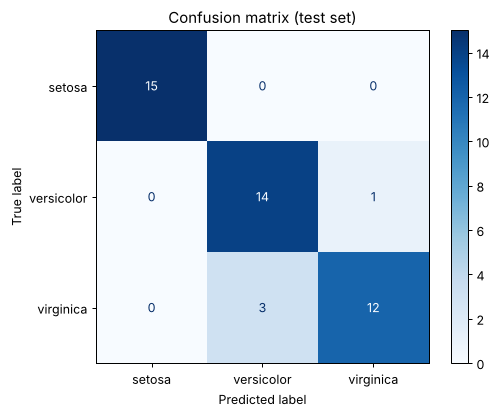

In [6]:
ConfusionMatrixDisplay.from_predictions(y_test, preds, display_labels=iris.target_names, cmap="Blues")
plt.title("Confusion matrix (test set)")
plt.show()

## 5. Result

With `test_size=0.3`, `n_estimators=100`, `max_depth=3`, `random_state=42` the model reaches **accuracy 0.9111** and **macro F1 0.9107** on the 45-sample test set. The errors are all between *versicolor* and *virginica*, the two overlapping classes; *setosa* is separated perfectly.